# Churn Prediction Model

------------------------------------
## **Dataset Description**
------------------------------------
* **customerID**: Unique identifier assigned to each customer.
* **gender**: Customer's gender (Male or Female).
* **SeniorCitizen**: Indicates whether the customer is a senior citizen (1 = Yes, 0 = No).
* **Partner**: Whether the customer has a partner (Yes or No).
* **Dependents**: Whether the customer has dependents (Yes or No).
* **tenure**: Number of months the customer has stayed with the company.
* **PhoneService**: Whether the customer subscribes to phone service.
* **MultipleLines**: Whether the customer has multiple phone lines.
* **InternetService**: Type of internet service (DSL, Fiber optic, or None).
* **OnlineSecurity**: Whether the customer subscribes to online security services.
* **OnlineBackup**: Whether the customer subscribes to online backup services.
* **DeviceProtection**: Whether the customer subscribes to device protection services.
* **TechSupport**: Whether the customer subscribes to technical support services.
* **StreamingTV**: Whether the customer subscribes to TV streaming services.
* **StreamingMovies**: Whether the customer subscribes to movie streaming services.
* **Contract**: Customer's contract type (Month-to-month, One year, or Two year).
* **PaperlessBilling**: Whether the customer uses paperless billing.
* **PaymentMethod**: Payment method used by the customer.
* **MonthlyCharges**: Amount charged to the customer monthly.
* **TotalCharges**: Total charges accumulated over the customer's tenure.
* **Churn**: Whether the customer has left the company (Yes or No). This is the target variable for prediction.

In [265]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import glob 
import os
import re
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (precision_score,recall_score,f1_score,average_precision_score)

In [233]:

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: /Users/tisya_elan/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


In [234]:


csv=glob.glob(os.path.join(path,"*.csv")) #any fine path that ends with csv 

df = pd.read_csv(csv[0]) #cos there is only 1 csv file in the dataset

### Data Cleaning

In [235]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [236]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [237]:
#convert total charges to numeric

df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [238]:
df.drop_duplicates(inplace=True)

In [239]:
df.shape

(7043, 21)

In [240]:
#check if customer id is unique

print(df["customerID"].nunique())

7043


In [241]:
# change to snake case

df.columns = [
    re.sub(r'(?<!^)(?=[A-Z])', '_', col).lower()
    for col in df.columns
]

In [242]:
print(df.columns)

Index(['customer_i_d', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_t_v', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='str')


In [243]:
# fix customer_id, streaming_tv
df.rename(columns={"customer_i_d":"customer_id","streaming_t_v":"streaming_tv"},inplace=True)

In [244]:

#replace senior citizen with yes or no so can group with other categorical variables and perform cross tab
df["senior_citizen"]=df["senior_citizen"].replace({1:"Yes",0:"No"})

In [245]:
df["senior_citizen"]=df["senior_citizen"].astype("str")

In [246]:
df.isna().sum()

customer_id           0
gender                0
senior_citizen        0
partner               0
dependents            0
tenure                0
phone_service         0
multiple_lines        0
internet_service      0
online_security       0
online_backup         0
device_protection     0
tech_support          0
streaming_tv          0
streaming_movies      0
contract              0
paperless_billing     0
payment_method        0
monthly_charges       0
total_charges        11
churn                 0
dtype: int64

In [247]:
#drop rows with na values for total charges

df.dropna(axis=0,inplace=True)



## EDA


#### univariate analysis

In [248]:
#split into categorical and numerical cols
# churn distribution

cat_cols=df.select_dtypes(include=["str"]).columns.tolist()
num_cols=df.select_dtypes(include=["int64","float64"]).columns.tolist()

#remove customer if

cat_cols.remove("customer_id")


In [249]:
#summary stats

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7032.0,32.421786,24.545260,1.00,9.0000,29.000,55.0000,72.00
monthly_charges,7032.0,64.798208,30.085974,18.25,35.5875,70.350,89.8625,118.75
total_charges,7032.0,2283.300441,2266.771362,18.80,401.4500,1397.475,3794.7375,8684.80


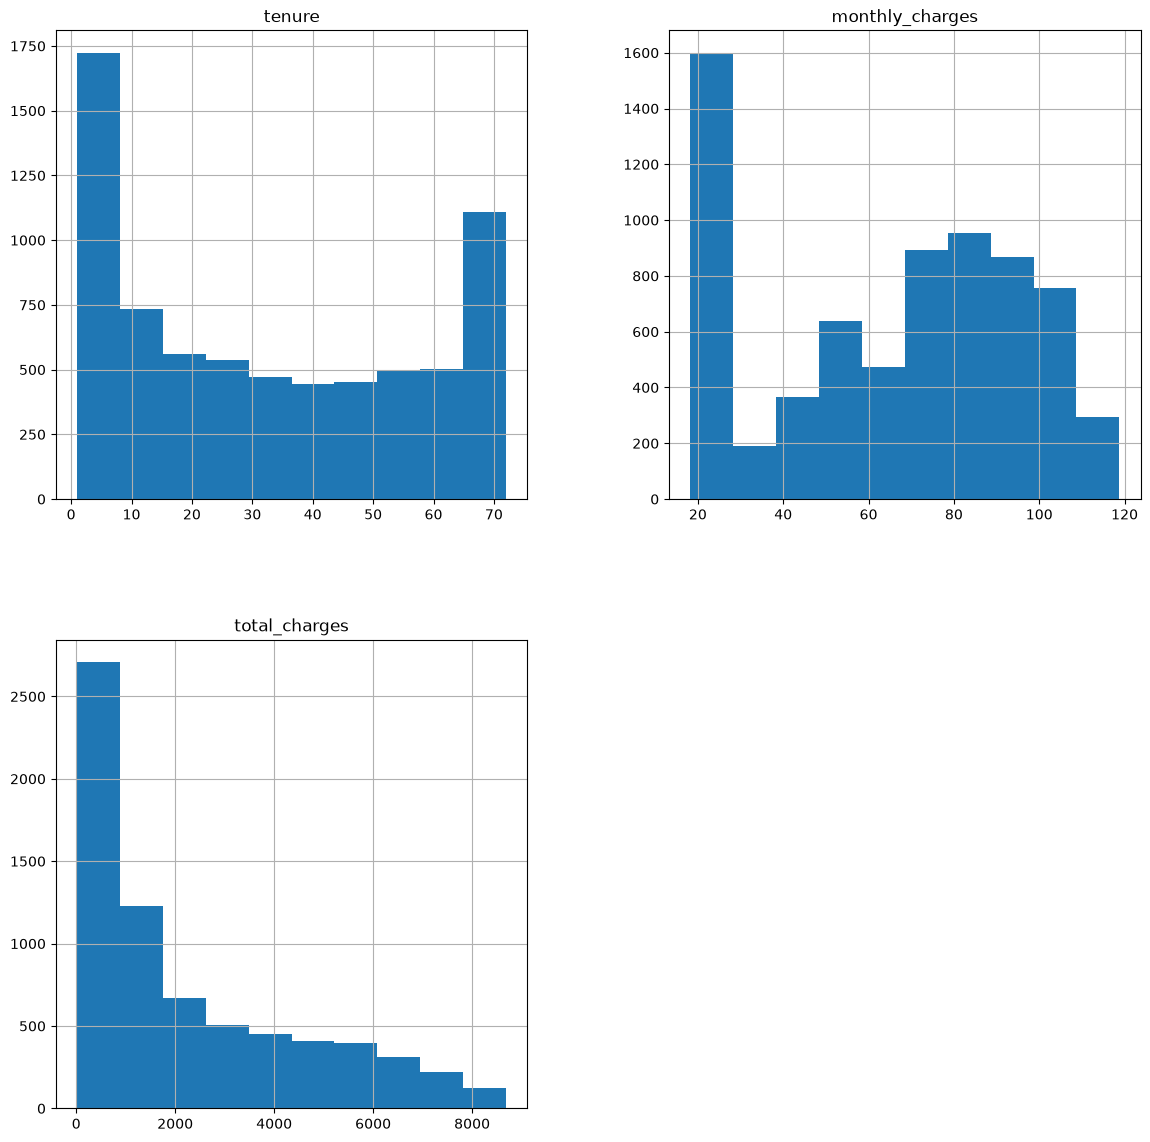

In [250]:
#create historgram
df[["tenure","monthly_charges","total_charges"]].hist(figsize=(14,14))
plt.show()

In [251]:
#univariate analysis for categorical variables

for i in cat_cols:
    print(df[i].value_counts(normalize=True))
    print("*" * 40)

gender
Male      0.504693
Female    0.495307
Name: proportion, dtype: float64
****************************************
senior_citizen
No     0.8376
Yes    0.1624
Name: proportion, dtype: float64
****************************************
partner
No     0.517491
Yes    0.482509
Name: proportion, dtype: float64
****************************************
dependents
No     0.701507
Yes    0.298493
Name: proportion, dtype: float64
****************************************
phone_service
Yes    0.903299
No     0.096701
Name: proportion, dtype: float64
****************************************
multiple_lines
No                  0.481371
Yes                 0.421928
No phone service    0.096701
Name: proportion, dtype: float64
****************************************
internet_service
Fiber optic    0.440273
DSL            0.343572
No             0.216155
Name: proportion, dtype: float64
****************************************
online_security
No                     0.497298
Yes                    0.2

#### bivariate and multivariate analysis


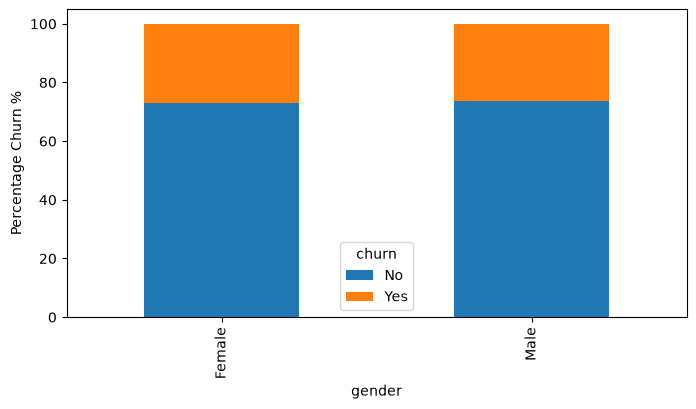

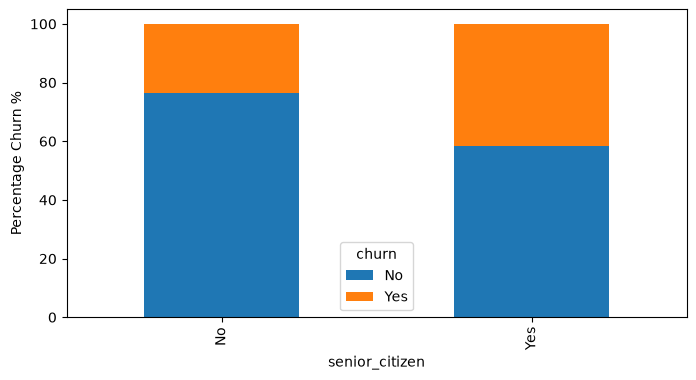

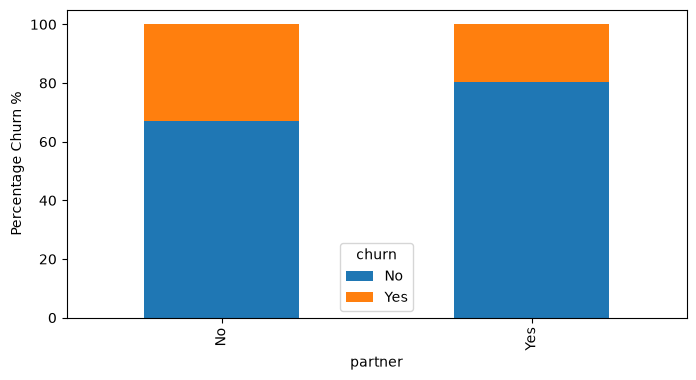

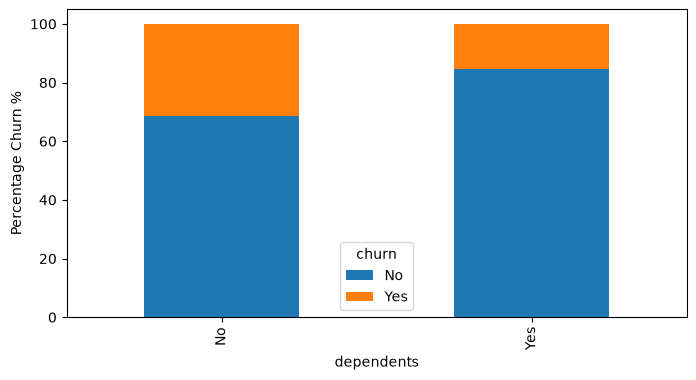

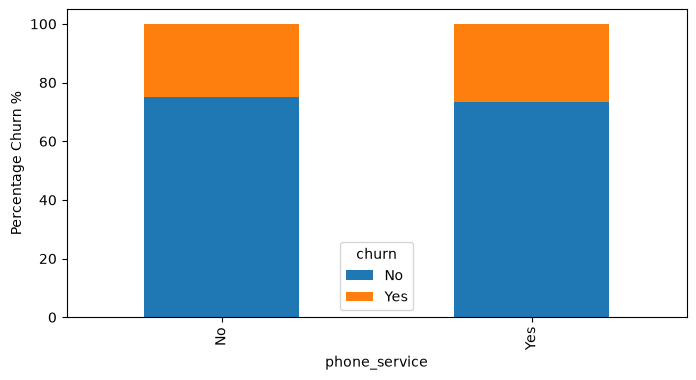

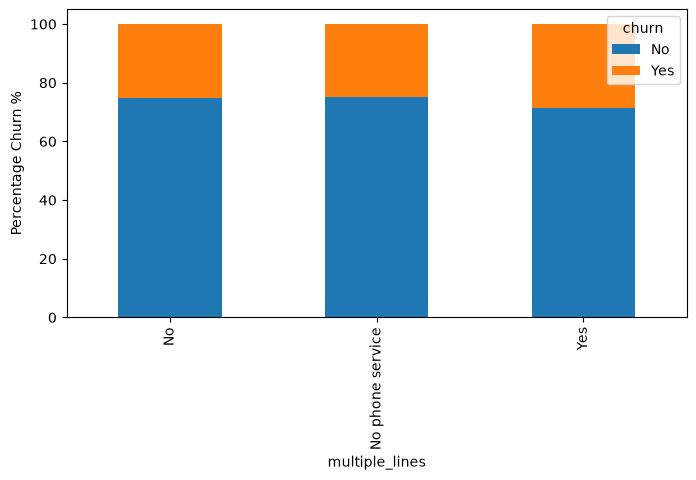

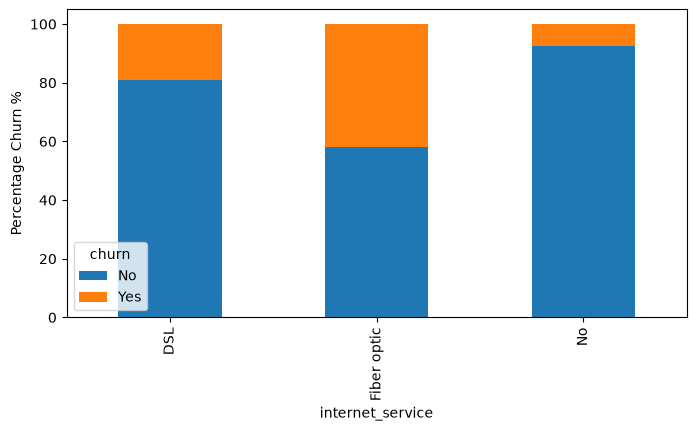

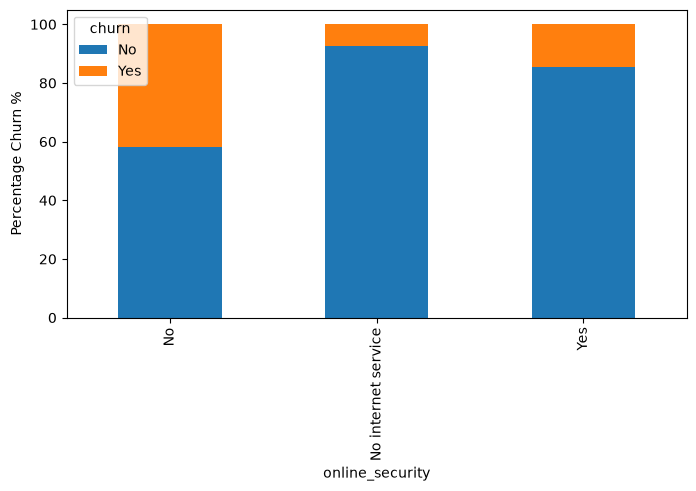

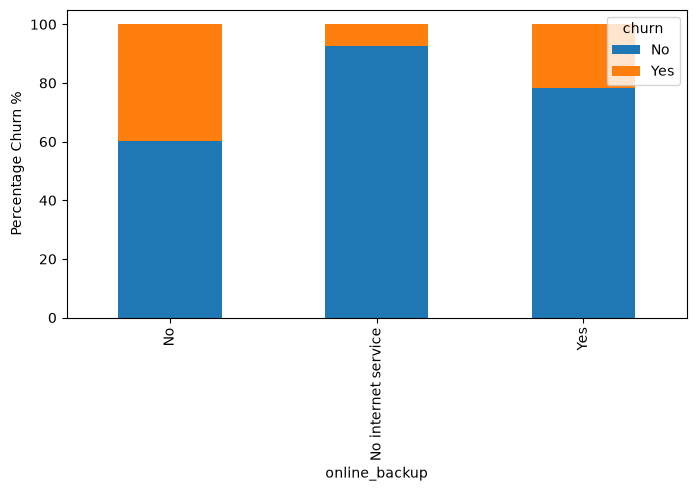

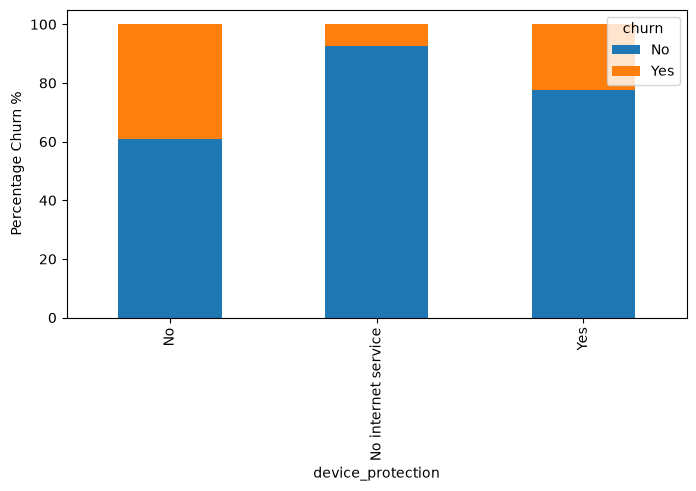

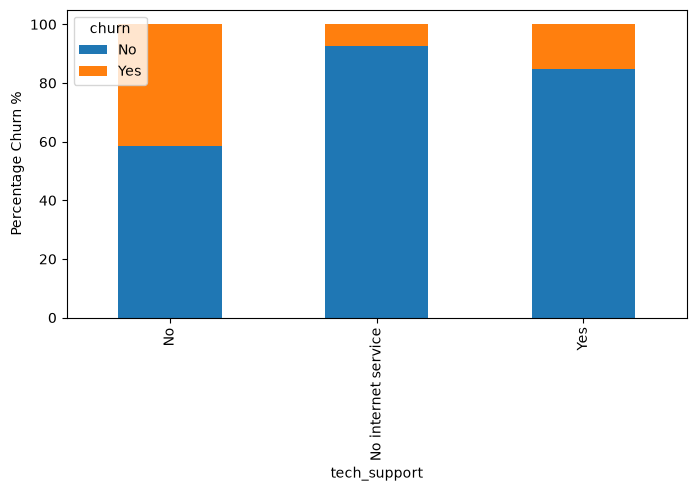

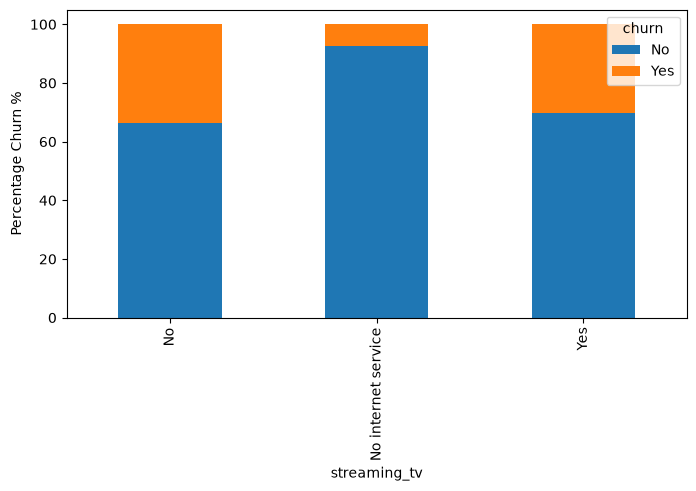

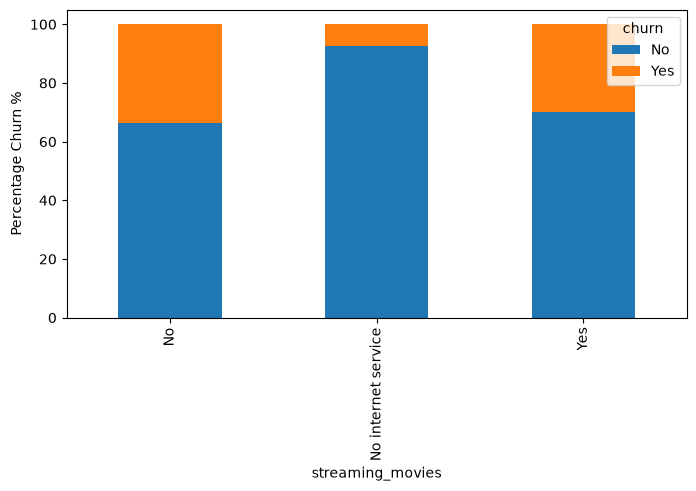

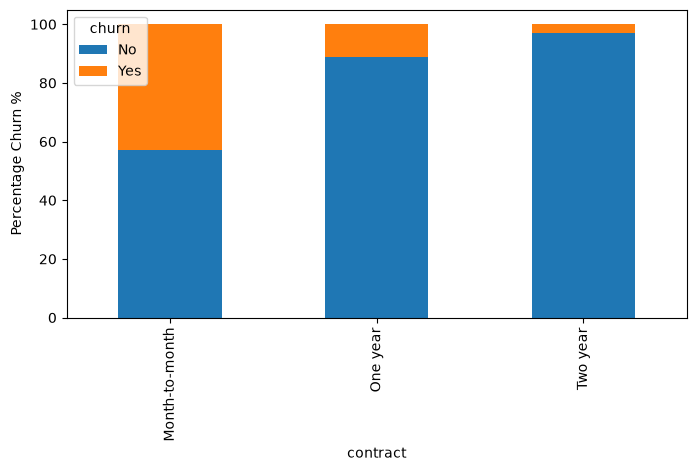

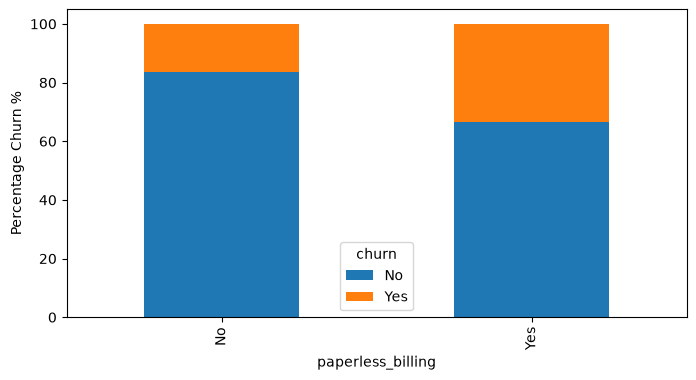

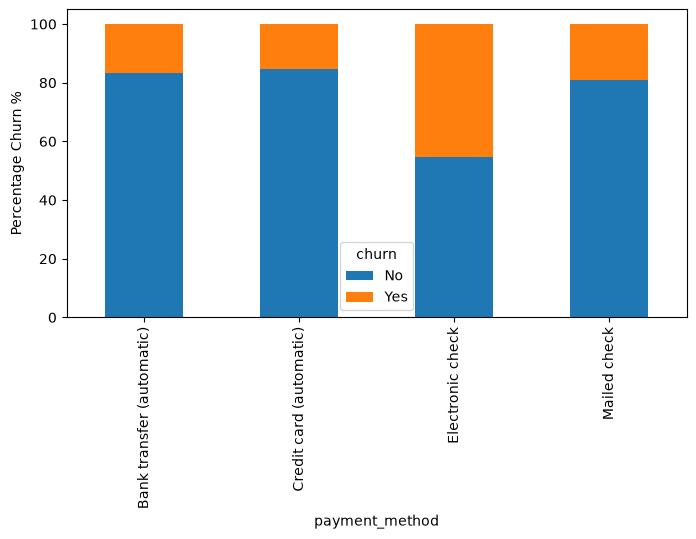

In [252]:
for i in cat_cols:
    if i !="churn":
        (pd.crosstab(df[i],df['churn'],normalize="index")*100).plot(kind="bar",figsize=(8,4),stacked=True)
        plt.ylabel("Percentage Churn %")

In [253]:
# mean of numerical variables goruped by churn

df.groupby(['churn'])[num_cols].mean()


,tenure,monthly_charges,total_charges
churn,,,
No,37.650010,61.307408,2555.344141
Yes,17.979133,74.441332,1531.796094


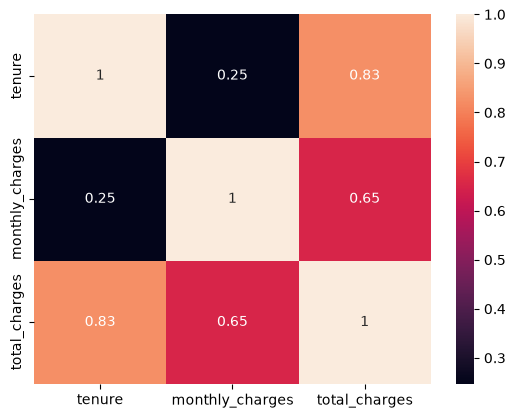

In [254]:
# plot correlation matrix 

corr=df[num_cols].corr()
sns.heatmap(corr,annot=True)
plt.show()

## Data Preprocessing

always perform encoding after and standardisation after train test split! it causes data leakage cos u have to calculate mean and standard deviation across the entire dataset

In [255]:
#map churn first
df["churn"] = df["churn"].map({"No": 0, "Yes": 1})

# train test split

X=df.drop(columns=["customer_id","churn"])
y=df["churn"]

#use stratify to preserve distribution of churn/no churn for both test and training sets
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)







In [256]:
#remove churn from cat_cols

cat_cols.remove("churn")

In [257]:
# column transformer allows you to preprocess different columns of data at the same time
# handles how columns are transformed 

preprocessor=ColumnTransformer([
    ("cat",OneHotEncoder(handle_unknown="ignore"),cat_cols),
    ("num",StandardScaler(),num_cols)
])



## Model Selection

### Logistic Regression

In [258]:
#pipeline combines preprocessing and model into one workflow 

lr_model=Pipeline(
[("preprocessor",preprocessor),
("classifier",LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced" #balanced gives greater wight to the minority class 
))
])

#train the model
lr_model.fit(X_train,y_train)

#predict on test model
lr_pred=lr_model.predict(X_test)
lr_scores=lr_model.predict_proba(X_test)[:,1] #probability of chuing

In [261]:
# zero division allows to return a 0 instead of raising a warning or error 
def compute_metrics(y_actual,y_pred,y_scores):
       return {
        "Precision": precision_score(y_actual, y_pred, zero_division=0),
        "Recall": recall_score(y_actual, y_pred, zero_division=0),
        "F1": f1_score(y_actual, y_pred, zero_division=0),
        "PR-AUC (Average Precision)": average_precision_score(y_actual, y_scores)
    }

In [263]:
metrics=compute_metrics(y_test,lr_pred,lr_scores)
print(metrics)

{'Precision': 0.4901315789473684, 'Recall': 0.7967914438502673, 'F1': 0.6069246435845214, 'PR-AUC (Average Precision)': 0.6182400601367767}


### SVM 

In [268]:
#rbf kernel allows for curnved boundary approach
# higher c push to model to fit the training data more closely (overfitting), lower c allows for more training errors
#c=1 is the middle 

svm_model=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",SVC(
        kernel="rbf" ,
        C=1.0,
        class_weight="balanced",
        random_state=42,
        probability=True
    ))
])


#train the model
svm_model.fit(X_train,y_train)

#predict on test model
svm_pred=svm_model.predict(X_test)
svm_scores=svm_model.predict_proba(X_test)[:,1]



/Users/tisya_elan/Library/Mobile Documents/com~apple~CloudDocs/Workspace/Projects/churn_prediction/venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [269]:
# get metrics

metrics=compute_metrics(y_test,svm_pred,svm_scores)

### XGBoost 

In [ ]:

xgb_model=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",XGBClassifier(
        n_estimators,
        objective="binary:logistic",
        random_state=42)
    )])

xgb_pred=xgb_model.fit(X_train, y_train)
xgb_scores=xgb_model.predict_proba(X_test)[:, 1]


NameError: name 'n_estimators' is not defined

In [ ]:
# get metrics
metrics=compute_metrics(y_test,xgb_pred,xgb_scores)

### Hyperparameter tuning
* for best model

In [ ]:
#next steps

# add mlflow 
# refactor scripts
